<a href="https://colab.research.google.com/github/priscilla-stn/desafios_tecnicos/blob/main/Desafio_2/Desafio2_Estatistica_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Célula 01 - Importações**
**O que esta célula faz:** importa as bibliotecas que o notebook usa (arquivos, Google Colab, pandas e gráficos) e define configurações gerais, que valem para todos os gráficos. **Não tem lacunas:** copie e execute.

In [77]:
# ---------- Bibliotecas: ferramentas prontas que o Python usa ----------
import warnings                    # esconde avisos técnicos para não distrair
from pathlib import Path           # manipula caminhos de arquivos e pastas
import shutil                      # manipula arquivos e pastas (ex.: mover, copiar, apagar)

# Estas linhas servem para trabalhar no Google Colab (conectar ao Drive e enviar arquivos)
from google.colab import drive     # conecta o Google Drive ao Colab (para ler e salvar arquivos)
from google.colab import files     # (files) envia arquivos do seu computador para o Colab

# Bibliotecas de análise de dados e de gráficos
import pandas as pd                # tabelas de dados (DataFrame)
import seaborn as sns              # gráficos bonitos e simples
import matplotlib.pyplot as plt    # ajustes nos gráficos (título, linhas...)

# ---------- Configurações gerais (valem para todos os gráficos abaixo) ----------
warnings.filterwarnings("ignore")           # esconde avisos técnicos para não distrair
sns.set_theme(style="whitegrid")            # deixa todos os gráficos com um visual limpo
plt.rcParams["figure.figsize"] = (8, 6)    # tamanho padrão dos gráficos (largura, altura)



### **Célula 02 - Carregar os Dados**
**O que esta célula faz:** conecta o Google Drive, guarda os CSV na pasta Colab Notebooks/desafios/dados e lê os dois arquivos em DataFrames: df_dimensao e df_fato. Os nomes das tabelas são os mesmos dos arquivos, sem o .csv.

- Na primeira execução, o Colab pede autorização para acessar o Drive.
- Se algum arquivo ainda não estiver na pasta, abre a janela de seleção: escolha os 2 CSV de uma vez. O código identifica cada um pelo nome (o nome do arquivo precisa conter o nome da tabela) e salva já com o nome certo.
- Nas próximas execuções, lê direto do Drive, sem pedir envio.

In [78]:
# Nomes das tabelas do seu tema (veja a tabela acima), iguais aos nomes dos arquivos CSV.
NOME_TABELA_DIMENSAO = "clientes"   # ex.: "livros"
NOME_TABELA_FATO = "chamados"           # ex.: "emprestimos"

# ---------- 1) Conectando ao Google Drive ----------
drive.mount("/content/drive")      # vai pedir autorização na primeira vez

# ---------- 2) Dizendo onde os arquivos estão guardados ----------
pasta_dados = Path("/content/drive/MyDrive/Colab Notebooks/desafios/dados")   # pasta onde a base fica guardada no Drive
pasta_dados.mkdir(parents=True, exist_ok=True)                                # cria a pasta "dados" se faltar

# O "/" junta a pasta com o nome do arquivo (o nome vem da variável de cada tabela).
caminho_dimensao = pasta_dados / f"{NOME_TABELA_DIMENSAO}.csv"
caminho_fato = pasta_dados / f"{NOME_TABELA_FATO}.csv"

# ---------- 3) Se faltar algum arquivo, envia os dois de uma vez e o código separa ----------
if not caminho_dimensao.exists() or not caminho_fato.exists():
    print(f"Selecione os arquivos CSV ({NOME_TABELA_DIMENSAO} e {NOME_TABELA_FATO}). Pode escolher os dois de uma vez:")
    enviados = files.upload()                                  # abre o seletor; aceita vários arquivos

    for nome_enviado in enviados:                              # percorre cada arquivo enviado
        if NOME_TABELA_DIMENSAO in nome_enviado.lower():       # o nome contém o da dimensão? salva como dimensão
            shutil.move(nome_enviado, caminho_dimensao)        # salva já com o nome da tabela
            print(f"{nome_enviado} -> {caminho_dimensao.name}")
        elif NOME_TABELA_FATO in nome_enviado.lower():         # o nome contém o da fato? salva como fato
            shutil.move(nome_enviado, caminho_fato)
            print(f"{nome_enviado} -> {caminho_fato.name}")
        else:                                                  # nome que não combina com nenhuma tabela
            print(f"Ignorado: {nome_enviado} (o nome não contém '{NOME_TABELA_DIMENSAO}' nem '{NOME_TABELA_FATO}')")

# Confere se os dois arquivos estão no Drive antes de ler.
for caminho in [caminho_dimensao, caminho_fato]:
    if not caminho.exists():
        raise FileNotFoundError(f"Falta o arquivo {caminho.name}. Execute a célula de novo e envie-o.")

# ---------- 4) Lendo os dois arquivos ----------
df_dimensao = pd.read_csv(caminho_dimensao)
df_fato = pd.read_csv(caminho_fato)

print(NOME_TABELA_DIMENSAO, "->", len(df_dimensao), "linhas")
print(NOME_TABELA_FATO, "->", len(df_fato), "linhas")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
clientes -> 10400 linhas
chamados -> 42000 linhas


### **Célula 03 - Conhecendo a tabela dimensão**
**O que esta célula faz:** mostra quantas linhas e colunas tem a tabela dimensão e as 5 primeiras linhas. Olhe a chave primária e as colunas de cadastro. **Não tem lacunas.**

In [79]:
# Quantas linhas (registros do cadastro) e colunas (variáveis) tem a tabela dimensão?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_dimensao.shape
print(f"A tabela dimensão tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_dimensao.head())


A tabela dimensão tem 10400 linhas e 4 colunas (variáveis)


,cliente_id,segmento,canal_preferido,data_cadastro
0,1,pequena_empresa,chat,2019-03-01
1,2,pessoa_fisica,chat,2024-04-22
2,3,pessoa_fisica,telefone,2026-05-04
3,4,pequena_empresa,telefone,2025-06-09
4,5,pessoa_fisica,email,2025-06-28


### **Célula 04 - Conhecendo a tabela fato**
**O que esta célula faz:** o mesmo para a tabela fato. Olhe a chave estrangeira, as datas e as colunas numéricas. **Não tem lacunas.**

In [80]:
# Quantas linhas (eventos) e colunas (variáveis) tem a tabela fato?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_fato.shape
print(f"A tabela fato tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_fato.head())

A tabela fato tem 42000 linhas e 8 colunas (variáveis)


,chamado_id,cliente_id,data_hora_abertura,canal,motivo,tempo_atendimento_min,nota_satisfacao,resolvido_primeiro_contato
0,1,1180,2026-05-08 06:25:57,chat,solicitacao_tecnica,17,2,False
1,2,5899,2026-05-21 11:21:58,telefone,duvida,21,2,False
2,3,195,2025-03-16 18:37:14,telefone,reclamacao,43,3,False
3,4,3216,2025-04-09 02:17:26,presencial,solicitacao_tecnica,13,5,True
4,5,5598,2026-07-05 18:46:00,chat,elogio,15,3,True


### **Célula 05 - Tipos das colunas**
**O que esta célula faz:** mostra o tipo de cada coluna e quantos valores estão preenchidos.


In [81]:
# 1) Tipo de cada coluna e quantidade de valores preenchidos. Compare com o esquema do plano do tema.
df_fato.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Data columns (total 8 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   chamado_id                  42000 non-null  int64 
 1   cliente_id                  42000 non-null  int64 
 2   data_hora_abertura          42000 non-null  object
 3   canal                       42000 non-null  object
 4   motivo                      42000 non-null  object
 5   tempo_atendimento_min       42000 non-null  int64 
 6   nota_satisfacao             42000 non-null  int64 
 7   resolvido_primeiro_contato  42000 non-null  bool  
dtypes: bool(1), int64(4), object(3)
memory usage: 2.3+ MB


### **Célula 06 - Valores ausentes**
**O que esta célula faz:** conta os valores ausentes de cada coluna da tabela fato.

In [82]:
# 2) Valores ausentes por coluna (tabela fato).
print("\nValores ausentes por coluna:")
print(df_fato.isna().sum())


Valores ausentes por coluna:
chamado_id                    0
cliente_id                    0
data_hora_abertura            0
canal                         0
motivo                        0
tempo_atendimento_min         0
nota_satisfacao               0
resolvido_primeiro_contato    0
dtype: int64


### **Célula 07 - Linhas duplicadas**
**O que esta célula faz:** conta os registros repetidos da tabela fato.


In [83]:
# 3) Linhas duplicadas (tabela fato).
print("\nLinhas duplicadas:", df_fato.duplicated().sum())


Linhas duplicadas: 0


### **Célula 08 - Chave estrangeira**
**O que esta célula faz:** confere se todo registro da fato aponta para um ID que existe na dimensão. Preencha com os nomes das colunas que você identificou na documentação do seu tema.

In [84]:
# 4) Chave estrangeira: todos os registros da tabela fato devem apontar para um ID que existe na tabela dimensão.
COLUNA_FK = "cliente_id"        # ex.: "livro_id" (coluna da fato que referencia a dimensão)
COLUNA_ID = "cliente_id"   # ex.: "livro_id" (coluna de ID da dimensão)
print("\nChaves estrangeiras que batem:", df_fato[COLUNA_FK].isin(df_dimensao[COLUNA_ID]).all())


Chaves estrangeiras que batem: True


**Leitura da conferência**

- A tabela de fato possui 42.000 registros e 8 colunas, sem linhas duplicadas.
- A chave estrangeira cliente_id da tabela fato corresponde a chave primária cliente_id da tabela dimensão. Todos os registros estão relacionados corretamente.
- A coluna de análise tempo_atendimento_min não apresenta valores ausentes.
- As demais colunas não apresentam valores ausentes, portanto não se identificaram problemas de preenchimento na base, não se identificaram campos vazios que precisem ser investigados para determinar se são erros, não foi identificado nenhum problema de preenchimento nos dados analisados.

### **Célula 09 - Checar a coluna numérica**
**O que esta célula faz:** guarda a coluna numérica escolhida no Passo 1 como uma série (serie_numerica) e mostra quantos valores estão preenchidos e quantos estão ausentes.

In [85]:
# Coluna numérica escolhida no Passo 1 (nome EXATO, como está no esquema do tema).
COLUNA_NUMERICA = "tempo_atendimento_min"

# A coluna escolhida, como uma série (uma coluna do DataFrame).
serie_numerica = df_fato[COLUNA_NUMERICA]
print("Valores preenchidos:", serie_numerica.count(), "| ausentes:", serie_numerica.isna().sum())

Valores preenchidos: 42000 | ausentes: 0


### **Célula 10 - Medidas estatísticas**
**O que esta célula faz:** calcula média, mediana, moda, desvio padrão, variância, mínimo, máximo e amplitude da coluna escolhida. O pandas ignora os valores ausentes no cálculo. **Não tem lacunas.**



In [86]:
# Medidas de Tendência central e dispersão.
medidas = pd.Series({
    "Média": serie_numerica.mean(),
    "Mediana": serie_numerica.median(),
    "Moda": serie_numerica.mode()[0],            # se houver empate, a primeira será selecionada
    "Desvio padrão": serie_numerica.std(),
    "Variância": serie_numerica.var(),
    "Mínimo": serie_numerica.min(),
    "Máximo": serie_numerica.max(),
    "Amplitude": serie_numerica.max() - serie_numerica.min(),
}).round(2)
display(medidas)

# Média muito diferente da mediana é sinal de valores extremos ou de dados assimétricos.
print("Média - mediana:", round(medidas["Média"] - medidas["Mediana"], 2))

,0
Média,15.60
Mediana,13.00
Moda,9.00
Desvio padrão,11.28
Variância,127.24
Mínimo,1.00
Máximo,107.00
Amplitude,106.00


Média - mediana: 2.6


**Insights**
* **A média de tempo_atendimento_min é 15,60 minutos**. O tempo médio para realizar um atendimento é de 15,60 minutos.

- **A mediana de tempo_atendimento_min é 13 minutos**. Metade dos atendimentos são feitos em até 13 minutos, enquanto a outra metade leva 13 minutos ou mais. Como a média é maior que a mediana, isso indica que alguns atendimentos mais demorados podem aumentar a média.

- **O desvio padrão de tempo_atendimento_min é 11,28 minutos**. O resultado demonstra que existe uma variação considerável na duração dos atendimentos, alguns são resolvidos mais rápido, enquanto outros levam mais tempo, não possuindo tempo semelhantes.

- **Decisão final:** Como os chamados não possuem o mesmo tempo de atendimento, é necessário verificar o que faz alguns atendimentos demorarem mais que os outros, buscando formas de tornar o processo de atendimento mais rápido e eficiente.

### **Célula 11 - Juntar a fato com a dimensão**
**O que esta célula faz:** junta a tabela fato com a dimensão pela chave estrangeira (COLUNA_FK, da fato, com COLUNA_ID, da dimensão) e guarda o resultado em df_completo. As duas tabelas precisam ter o mesmo número de linhas depois da junção. Se aumentar, a junção duplicou registros. **Não tem lacunas.**


In [87]:
# Junta a fato com a dimensão: cada registro da fato recebe as colunas do seu cadastro.
df_completo = df_fato.merge(df_dimensao, left_on=COLUNA_FK, right_on=COLUNA_ID, how="left", suffixes=("", "_dim"))

print("Linhas da fato:", len(df_fato), "| depois da junção:", len(df_completo))   # precisam ser iguais


Linhas da fato: 42000 | depois da junção: 42000


In [88]:
df_completo.head()

,chamado_id,cliente_id,data_hora_abertura,canal,motivo,tempo_atendimento_min,nota_satisfacao,resolvido_primeiro_contato,segmento,canal_preferido,data_cadastro
0,1,1180,2026-05-08 06:25:57,chat,solicitacao_tecnica,17,2,False,pessoa_fisica,email,2024-12-30
1,2,5899,2026-05-21 11:21:58,telefone,duvida,21,2,False,grande_empresa,chat,2022-09-12
2,3,195,2025-03-16 18:37:14,telefone,reclamacao,43,3,False,pessoa_fisica,email,2021-11-22
3,4,3216,2025-04-09 02:17:26,presencial,solicitacao_tecnica,13,5,True,pessoa_fisica,email,2022-03-10
4,5,5598,2026-07-05 18:46:00,chat,elogio,15,3,True,pessoa_fisica,telefone,2020-10-03


### **Célula 12 - Comparar grupos por uma coluna de fato**
**O que esta célula faz:** calcula quantidade, média, mediana e desvio padrão da coluna numérica em cada grupo de uma coluna categórica da fato, do maior para o menor valor médio.

In [89]:
# Coluna categórica usada para comparar (da fato ou da dimensão). Poucos valores diferentes funcionam melhor.
COLUNA_GRUPO = "resolvido_primeiro_contato"

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)


,count,mean,median,std
resolvido_primeiro_contato,,,,
False,19684,23.46,22.0,11.59
True,22316,8.67,9.0,4.28


**Leitura por resolvido_primeiro_contato**

- A maior média foi dos atendimentos que não foram resolvidos no primeiro contato com 23,46 minutos, a mediana de atendimentos não resolvidos no primeiro contato foi de 22 minutos, comprovando que esses atendimentos costumam demorar mais.

- Os atendimentos não resolvidos no primeiro contato representam o maior desvio padrão com 11,59 minutos, o que demonstra que o tempo desses atendimentos varia mais.

- Existe uma diferença relevante entre as médias, pois os atendimentos não resolvidos no primeiro contato levam em média 23,46 minutos e os atendimentos resolvidos no primeiro contato levam em média 8,67 minutos, isso indica que no primeiro contato o atendimento leva menos tempo em média.


### **Célula 13 - Comparar grupos por uma coluna de dimensão**
**O que esta célula faz:** a mesma comparação, agora com uma coluna da dimensão, que só está disponível em df_completo por causa da junção da Célula 11. Escreva também a leitura, no mesmo modelo.

In [90]:
COLUNA_GRUPO = "segmento"     # coluna da dimensão: só existe em df_completo por causa da junção

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)


,count,mean,median,std
segmento,,,,
grande_empresa,2066,15.70,13.0,11.56
pessoa_fisica,31534,15.62,13.0,11.29
pequena_empresa,8400,15.53,13.0,11.18


**Leitura por segmento**

- A maior média foi do segmento de grandes empresas com 15,70 minutos, a mediana foi de 13,00 minutos, igual à dos outros segmentos, mostrando que o tempo de atendimento é semelhante.

- O segmento de grandes empresas teve o maior desvio padrão com 11,56 minutos, o que indica que a duração dos atendimentos varia um pouco mais nesse segmento.

- As médias dos três segmentos são parecidas, indicando que o segmento não apresenta uma diferença relevante no tempo médio de atendimento.


### **Célula 14 - Regra do IQR**
**O que esta célula faz:** usa a regra do intervalo interquartil (IQR) para marcar valores muito distantes da faixa central e mostra os limites, a quantidade de candidatos a outlier e os valores extremos. **Não tem lacunas.**

In [91]:
# Faixa central dos dados: do 1º ao 3º quartil (25% e 75%).
q1 = serie_numerica.quantile(0.25)
q3 = serie_numerica.quantile(0.75)
iqr = q3 - q1

# Regra usual: fora de [Q1 - 1,5 x IQR ; Q3 + 1,5 x IQR] é candidato a outlier.
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Cálculo do número de outliers
sem_outliers = serie_numerica[(serie_numerica >= limite_inferior) & (serie_numerica <= limite_superior)]
qtd_outliers = serie_numerica.count() - sem_outliers.count()

print(f"Limites: {limite_inferior:.2f} a {limite_superior:.2f}")
print(f"Outliers: {qtd_outliers} de {serie_numerica.count()} valores")
print("Maiores valores:", serie_numerica.nlargest(5).tolist())
print("Menores valores:", serie_numerica.nsmallest(5).tolist())

Limites: -14.00 a 42.00
Outliers: 1247 de 42000 valores
Maiores valores: [107, 96, 96, 95, 93]
Menores valores: [1, 1, 1, 1, 1]


### **Célula 15 - Medidas com e sem os candidatos a outlier**
**O que esta célula faz:** compara média, mediana e desvio padrão com e sem os valores marcados na Célula 14. **Não tem lacunas.**

In [92]:
# Compara as medidas com e sem os candidatos a outlier.
comparacao = pd.DataFrame({
    "Com outliers": [serie_numerica.mean(), serie_numerica.median(), serie_numerica.std()],
    "Sem outliers": [sem_outliers.mean(), sem_outliers.median(), sem_outliers.std()],
}, index=["Média", "Mediana", "Desvio padrão"]).round(2)
display(comparacao)

,Com outliers,Sem outliers
Média,15.60,14.50
Mediana,13.00,13.00
Desvio padrão,11.28,9.38


**Leitura e decisão registrada**

- A regra do IQR marcou 1.247 possíveis outliers, que representam os atendimentos acima de 42 minutos, ao retirar esses valores da comparação, a média passou de 15,60 minutos para 14,50 minutos, a mediana permaneceu em 13 minutos e o desvio padrão diminuiu de 11,28 minutos para 9,38 minutos.
- **Decisão:** manter os valores encontrados, pois podem representar atendimentos que realmente levaram mais tempo para serem concluídos, não há evidências de que sejam erros nos registros.
- **Valores ausentes:** não foram encontrados registros sem informação no tempo de atendimento, por isso não foi necessário preencher ou excluir nenhum registro.

### **Célula 16 - Assimetria (skew)**
**O que esta célula faz:** calcula o quanto a distribuição se inclina para um dos lados.


In [93]:
# Assimetria: perto de 0 = formato equilibrado; positiva = cauda para valores altos; negativa = para valores baixos.
print("Assimetria:", round(serie_numerica.skew(), 2))

Assimetria: 1.39


### **Célula 17 - Percentis**
**O que esta célula faz:** mostra até que valor ficam 10%, 25%, 50%, 75% e 90% dos registros.


In [94]:
# Percentis: por exemplo, 50% dos valores ficam na mediana ou abaixo dela.
print(serie_numerica.quantile([0.10, 0.25, 0.50, 0.75, 0.90]))

0.10     4.0
0.25     7.0
0.50    13.0
0.75    21.0
0.90    31.0
Name: tempo_atendimento_min, dtype: float64


### **Célula 18 - Quantidade de valores por faixa**
**O que esta célula faz:** divide os valores em 5 faixas de mesmo tamanho e conta quantos caem em cada uma.

In [95]:
# Quantidade de valores em 5 faixas de mesmo tamanho (a versão em texto de um histograma).
display(pd.cut(serie_numerica, bins=5).value_counts().sort_index())

,count
tempo_atendimento_min,
"(0.894, 22.2]",32710
"(22.2, 43.4]",8169
"(43.4, 64.6]",1018
"(64.6, 85.8]",92
"(85.8, 107.0]",11


**Leitura da distribuição**

- A assimetria foi de 1,39, indicando uma distribuição positiva. A maior parte dos atendimentos leva menos tempo para serem resolvidos e alguns atendimentos demoram mais tempo, formando uma cauda para o lado direito da distribuição.
- 75% dos atendimentos duram até 21 minutos e 90% dos atendimentos duram até 31 minutos.
- na primeira faixa de aproximadamente 1 a 22 minutos estão 32.710 atendimentos e nas quatro faixas seguintes mais altas acima de 22 minutos estão 9.290 atendimentos.
- Em palavras: A maioria dos atendimentos são resolvidos em até 22 minutos, enquanto uma quantidade menor demora mais de 22 minutos, apenas 10% dos atendimentos ultrapassam 31 minutos.

## **Recomendação**

**Pergunta de negócio:** Os atendimentos duram o mesmo tempo em todos os chamados? Ou alguns são mais longos? O que explica isso?


**Evidência 1:** A média dos atendimentos foi de 15,60 minutos enquanto a mediana foi de 13,00 minutos. Isso demonstra que alguns atendimentos mais demorados aumentam a média. O desvio padrão de 11,28 minutos indica uma diferença considerável entre o tempo dos atendimentos, monstrando que alguns atendimentos são rápidos enquanto outros levam mais tempo.

**Evidência 2:** A média dos atendimentos não resolvidos no primeiro contato foi de 23,46 minutos enquanto os resolvidos no primeiro contato foi de 8,67 minutos. O desvio padrão foi de 11,59 minutos nos atendimentos não resolvidos no primeiro contato e de 4,28 minutos nos atendimentos resolvidos no primeiro contato, isso indica que os atendimentos não resolvidos no primeiro contato costumam demorar mais e também apresentam maior diferença no tempo de atendimento.

**Recomendação em uma frase:** Investigar o que dificulta a resolução dos atendimentos no primeito contato e buscar melhorias nesse processo, para solucionar os problemas com mais rapidez, reduzir o tempo de atendimento e tornar o processo mais eficiente.

**Limites da análise:** Os dados são fictícios e servem para simular uma situação de atendimento. Foram identificados 1.247 atendimentos com duração superior a 42 minutos, os registros foram mantidos, pois podem representar atendimentos que realmente levaram mais tempo e não necessariamente erros nos dados. Todos os registros da coluna de tempo de atendimento estavam preenchidos e sem valores ausentes.



### **Célula 19 - Histograma**
**O que esta célula faz:** desenha o histograma da coluna analisada, com a curva da distribuição (kde=True) e as linhas da média (vermelha) e da mediana (verde tracejada).

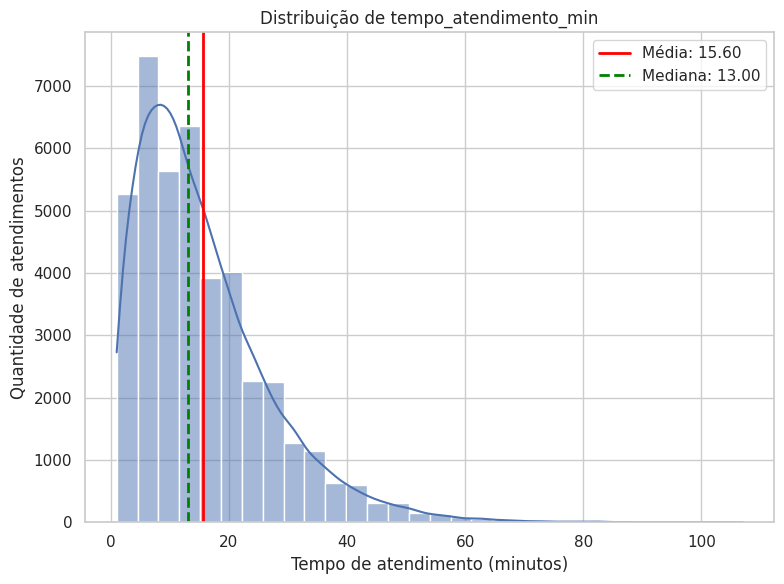

In [96]:
# Histograma: como os valores se distribuem, com a curva da distribuição e as linhas de média e mediana.
sns.histplot(serie_numerica.dropna(), bins=30, kde=True)
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.axvline(serie_numerica.median(), color="green", linestyle="--", linewidth=2, label=f"Mediana: {serie_numerica.median():.2f}")
plt.title(f"Distribuição de {COLUNA_NUMERICA}")
plt.xlabel("Tempo de atendimento (minutos)")        # lacuna: nome do eixo x, em linguagem simples
plt.ylabel("Quantidade de atendimentos")            # lacuna: nome do eixo y, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

**Insights**


* O histograma mostra que a maioria dos atendimentos tem duração menor e conforme o tempo aumenta a quantidade de atendimentos diminui, os chamados que demoram mais são demonstrados pela cauda longa à direita. A média de 15,60 minutos está a direita da mediana de 13,00 minutos, demonstrando que os atendimentos mais demorados elevam a média. O gráfico demonstra que a maioria dos atendimentos são feitos em menos tempo, porém alguns levam mais tempo para serem concluídos.



### **Célula 20 - Boxplot**
**O que esta célula faz:** desenha o boxplot: a caixa é a faixa central (25% a 75%) e os pontos fora são candidatos a outlier. A linha vermelha marca a média.

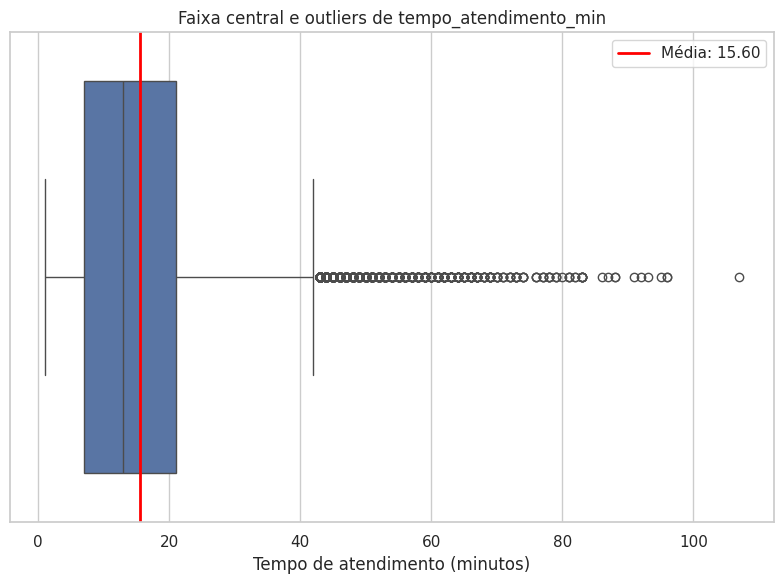

In [97]:
# Boxplot: a caixa é a faixa central (25% a 75%); os pontos fora são candidatos a outlier.
sns.boxplot(x=serie_numerica.dropna())
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.title(f"Faixa central e outliers de {COLUNA_NUMERICA}")
plt.xlabel("Tempo de atendimento (minutos)")        # lacuna: nome do eixo x, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

**Insights**


* O boxplot mostra que o tempo de atendimento está mais concentrado entre 7 e 21 minutos, a linha dentro da caixa mostra que a mediana foi de 13 minutos e a linha vermelha que a média foi de 15,60 minutos, o bigode esquerdo mostra os atendimentos com tempo menor de aproximadamente até 1 minuto, o bigode direito mostra os atendimentos com tempo maior de aproximadamente 42 minutos e os pontos depois do bigode direito são possíveis outliers, ou seja, atendimentos que demoraram mais que a maioria, chegando a 107 minutos. O gráfico demonstra que a maioria dos atendimentos levam um tempo menor, porém existem algus atendimentos que demoram muito mais que os demais, chegando a 107 minutos.

